# DATA 266 — CLIP: Caption–Image Similarity & Zero-Shot CIFAR-10 Classification

**Part 1 (5 pts):** Compare one caption against 1,000 CIFAR-10 test images (100 per class) using CLIP — load model → define caption → preprocess images → extract & L2-normalize embeddings → cosine similarity → visualize → findings.

**Part 2 (5 pts):** Zero-shot classification of the full CIFAR-10 test set (10,000 images) with prompt ensembling; report overall + per-class accuracy and a confusion matrix.

**Runtime:** Google Colab, T4 GPU (`Runtime → Change runtime type → T4 GPU`). End-to-end run ≈ 3–5 min.
All figures and metric files are written to `outputs/`.

## 0. Setup

In [1]:
import os, json, time, random, platform
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import Markdown, display

import transformers
from transformers import CLIPModel, CLIPProcessor
from torchvision.datasets import CIFAR10
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

# ---------------- Config ----------------
SEED        = 6638
MODEL_ID    = "openai/clip-vit-base-patch32"   # swap to "openai/clip-vit-large-patch14" for higher accuracy (slower)
N_PER_CLASS = 100                              # Part 1: images per class
BATCH_SIZE  = 256
OUT_DIR     = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
RUN_START = time.time()
print(f"torch {torch.__version__} | transformers {transformers.__version__} | device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))

# ---------------- Plot style ----------------
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def save(fig, name):
    path = os.path.join(OUT_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved → {path}")

torch 2.14.1+cu130 | transformers 5.22.1 | device: cuda (NVIDIA A100-SXM4-40GB)


## 1. Load the CLIP model
CLIP has two encoders trained contrastively on 400M image–text pairs: a ViT image encoder and a Transformer text encoder, each followed by a linear projection into a **shared 512-d embedding space**. Matching image/text pairs land close together (high cosine similarity).

In [2]:
model = CLIPModel.from_pretrained(MODEL_ID).to(DEVICE).eval()
if DEVICE == "cuda":
    model = model.half()                      # fp16 on T4: ~2x faster, same accuracy
MODEL_DTYPE = next(model.parameters()).dtype
processor = CLIPProcessor.from_pretrained(MODEL_ID)

LOGIT_SCALE = model.logit_scale.exp().item()  # learned temperature (≈100)
EMB_DIM = model.config.projection_dim
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"{MODEL_ID}: {n_params:.1f}M params | embedding dim = {EMB_DIM} | logit scale = {LOGIT_SCALE:.2f}")
print(f"image input size: {processor.image_processor.crop_size}")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

openai/clip-vit-base-patch32: 151.3M params | embedding dim = 512 | logit scale = 100.00
image input size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)


### Embedding helpers
Embeddings are computed as `projection(encoder(x).pooler_output)` and then **L2-normalized**, so a dot product equals cosine similarity.
(This calls the encoders directly, which behaves the same across `transformers` versions.)

In [3]:
@torch.no_grad()
def encode_images(pil_images, batch_size=BATCH_SIZE, desc="Encoding images"):
    feats = []
    for i in tqdm(range(0, len(pil_images), batch_size), desc=desc):
        batch = pil_images[i:i + batch_size]
        pixel_values = processor.image_processor(images=batch, return_tensors="pt")["pixel_values"]
        pixel_values = pixel_values.to(DEVICE, dtype=MODEL_DTYPE)
        pooled = model.vision_model(pixel_values=pixel_values).pooler_output
        emb = model.visual_projection(pooled)
        feats.append(F.normalize(emb.float(), dim=-1).cpu())
    return torch.cat(feats)                    # (N, EMB_DIM), unit norm

@torch.no_grad()
def encode_texts(texts):
    tok = processor.tokenizer(texts, padding=True, truncation=True, return_tensors="pt").to(DEVICE)
    pooled = model.text_model(input_ids=tok["input_ids"], attention_mask=tok["attention_mask"]).pooler_output
    emb = model.text_projection(pooled)
    return F.normalize(emb.float(), dim=-1).cpu()   # (T, EMB_DIM), unit norm

### Load CIFAR-10 (test split)
10,000 test images, 1,000 per class, 32×32 RGB.

In [4]:
test_set = CIFAR10(root="./data", train=False, download=True)
CLASSES = test_set.classes
labels_all = np.array(test_set.targets)
print(CLASSES)
print("test images:", len(test_set), "| per-class counts:", np.bincount(labels_all).tolist())

100%|██████████| 170M/170M [04:55<00:00, 577kB/s]


['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
test images: 10000 | per-class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


---
# Part 1 — Caption vs. 1,000 images (100 per class)

## 2. Define the caption

In [5]:
TARGET_CLASS = "dog"
CAPTION      = "a photo of a dog"
target_id    = CLASSES.index(TARGET_CLASS)
print(f'Caption: "{CAPTION}"  (matching class: {TARGET_CLASS}, id={target_id})')

Caption: "a photo of a dog"  (matching class: dog, id=5)


## 3. Preprocess multiple images
Sample **100 images per class** (seeded) → 1,000 images. The CLIP processor resizes the shortest side to 224 (bicubic), center-crops 224×224, and normalizes with CLIP's channel mean/std.

subset size: 1000 | per class: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
raw image: (32, 32) → preprocessed tensor: (1, 3, 224, 224)


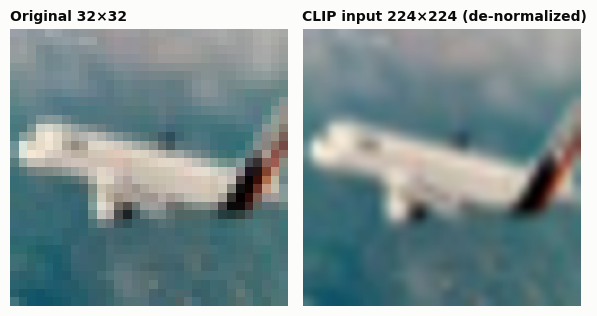

In [6]:
rng = np.random.default_rng(SEED)
subset_idx = np.concatenate([
    rng.choice(np.where(labels_all == c)[0], N_PER_CLASS, replace=False) for c in range(len(CLASSES))
])
subset_labels = labels_all[subset_idx]
subset_images = [Image.fromarray(test_set.data[i]) for i in subset_idx]
print("subset size:", len(subset_images), "| per class:", np.bincount(subset_labels).tolist())

# Show what preprocessing does to one image
example = processor.image_processor(images=subset_images[0], return_tensors="pt")["pixel_values"]
print("raw image:", subset_images[0].size, "→ preprocessed tensor:", tuple(example.shape))

mean = np.array(processor.image_processor.image_mean)[:, None, None]
std  = np.array(processor.image_processor.image_std)[:, None, None]
fig, axes = plt.subplots(1, 2, figsize=(6, 3.2))
axes[0].imshow(subset_images[0], interpolation="nearest"); axes[0].set_title("Original 32×32", fontsize=10)
axes[1].imshow(np.clip(example[0].numpy() * std + mean, 0, 1).transpose(1, 2, 0))
axes[1].set_title("CLIP input 224×224 (de-normalized)", fontsize=10)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Extract & normalize embeddings

In [7]:
t0 = time.time()
img_emb_p1 = encode_images(subset_images, desc="Part 1 images")   # (1000, D)
txt_emb_p1 = encode_texts([CAPTION])                               # (1, D)
p1_encode_sec = time.time() - t0

print("image embeddings:", tuple(img_emb_p1.shape), "| text embedding:", tuple(txt_emb_p1.shape))
print(f"norms → images: {img_emb_p1.norm(dim=-1).mean():.4f}, text: {txt_emb_p1.norm(dim=-1).item():.4f}  (≈1 after L2-normalization)")
print(f"encode time: {p1_encode_sec:.1f}s")

Part 1 images:   0%|          | 0/4 [00:00<?, ?it/s]

image embeddings: (1000, 512) | text embedding: (1, 512)
norms → images: 1.0000, text: 1.0000  (≈1 after L2-normalization)
encode time: 4.6s


## 5. Compute similarity scores
- **Cosine similarity** = dot product of unit vectors (raw CLIP cosines are compressed, typically ~0.1–0.35).
- **Scaled logit** = `logit_scale × cosine` — the value CLIP actually uses in its softmax.
- Retrieval quality of the caption: **Precision@100** (how many of the 100 highest-scoring images are dogs) and **ROC-AUC** (dog vs. not-dog ranking).

In [8]:
cos_sim = (img_emb_p1 @ txt_emb_p1.T).squeeze(1).numpy()     # (1000,)
scaled  = LOGIT_SCALE * cos_sim

per_class_stats = pd.DataFrame({
    "class": CLASSES,
    "mean_cos": [cos_sim[subset_labels == c].mean() for c in range(len(CLASSES))],
    "std_cos":  [cos_sim[subset_labels == c].std()  for c in range(len(CLASSES))],
    "min_cos":  [cos_sim[subset_labels == c].min()  for c in range(len(CLASSES))],
    "max_cos":  [cos_sim[subset_labels == c].max()  for c in range(len(CLASSES))],
}).sort_values("mean_cos", ascending=False).reset_index(drop=True)
per_class_stats["mean_scaled_logit"] = per_class_stats["mean_cos"] * LOGIT_SCALE

rank = np.argsort(-cos_sim)
is_target = subset_labels == target_id
prec_at_100 = is_target[rank[:N_PER_CLASS]].mean()
auc = roc_auc_score(is_target, cos_sim)

print(f'Caption: "{CAPTION}"')
print(f"cosine range: {cos_sim.min():.4f} – {cos_sim.max():.4f} | mean {cos_sim.mean():.4f}")
print(f"Precision@100 = {prec_at_100:.3f} | ROC-AUC ({TARGET_CLASS} vs rest) = {auc:.4f}\n")
display(per_class_stats.style.format({c: "{:.4f}" for c in ["mean_cos", "std_cos", "min_cos", "max_cos"]}
                                     | {"mean_scaled_logit": "{:.2f}"}))
per_class_stats.to_csv(f"{OUT_DIR}/part1_per_class_similarity.csv", index=False)

Caption: "a photo of a dog"
cosine range: 0.1546 – 0.2941 | mean 0.2200
Precision@100 = 0.760 | ROC-AUC (dog vs rest) = 0.9626



,class,mean_cos,std_cos,min_cos,max_cos,mean_scaled_logit
0,dog,0.2611,0.0127,0.2047,0.2899,26.11
1,cat,0.2401,0.0155,0.1832,0.2785,24.01
2,deer,0.2347,0.0167,0.1949,0.2941,23.47
3,frog,0.2292,0.0119,0.2054,0.2558,22.92
4,bird,0.2269,0.0137,0.1986,0.2752,22.69
5,horse,0.2191,0.0127,0.1922,0.2556,21.91
6,airplane,0.2027,0.0133,0.1659,0.2351,20.27
7,automobile,0.1978,0.0119,0.1594,0.2270,19.78
8,truck,0.1949,0.0114,0.1717,0.2341,19.49
9,ship,0.1933,0.0143,0.1546,0.2296,19.33


## 6. Visualize the results
### 6a. Most and least similar images (with scores)
Orange frame = image actually belongs to the caption's class.

saved → outputs/part1_top18.png


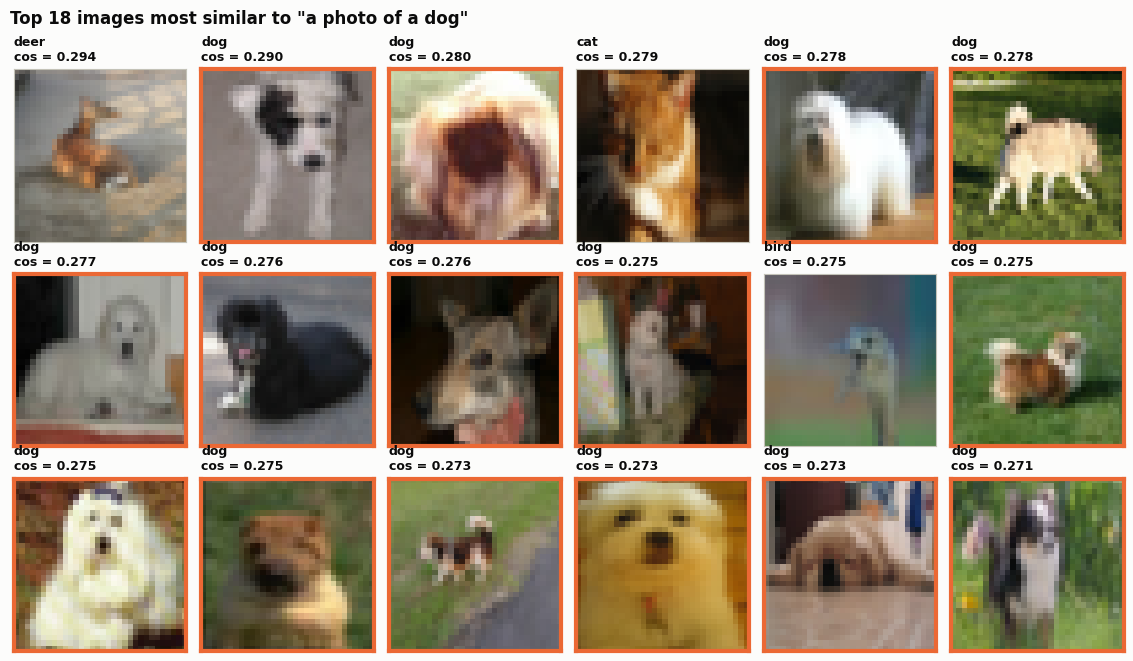

saved → outputs/part1_bottom12.png


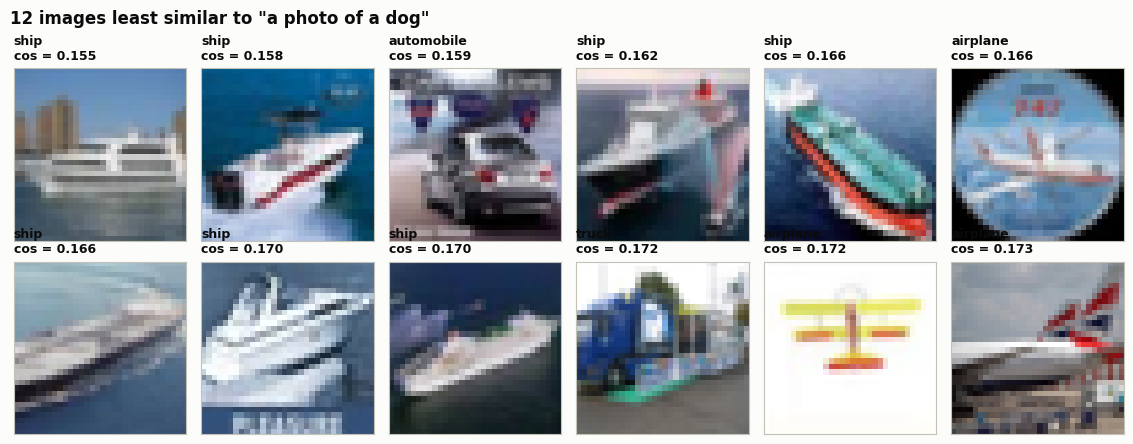

In [9]:
def plot_ranked(idx_list, title, fname, ncols=6):
    nrows = int(np.ceil(len(idx_list) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.9, nrows * 2.25))
    for ax, k in zip(axes.ravel(), idx_list):
        hit = subset_labels[k] == target_id
        ax.imshow(subset_images[k], interpolation="nearest")
        ax.set_title(f"{CLASSES[subset_labels[k]]}\ncos = {cos_sim[k]:.3f}", fontsize=9, color=INK)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(True); s.set_color(ORANGE if hit else AXIS); s.set_linewidth(3 if hit else 0.8)
    for ax in axes.ravel()[len(idx_list):]:
        ax.axis("off")
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    plt.tight_layout(); save(fig, fname); plt.show()

plot_ranked(rank[:18],  f'Top 18 images most similar to "{CAPTION}"',  "part1_top18.png")
plot_ranked(rank[-12:][::-1], f'12 images least similar to "{CAPTION}"', "part1_bottom12.png")

### 6b. Every class, side by side
6 random images per class (sorted by score) with their cosine similarity; the row label shows the class mean over all 100 images.

saved → outputs/part1_class_gallery.png


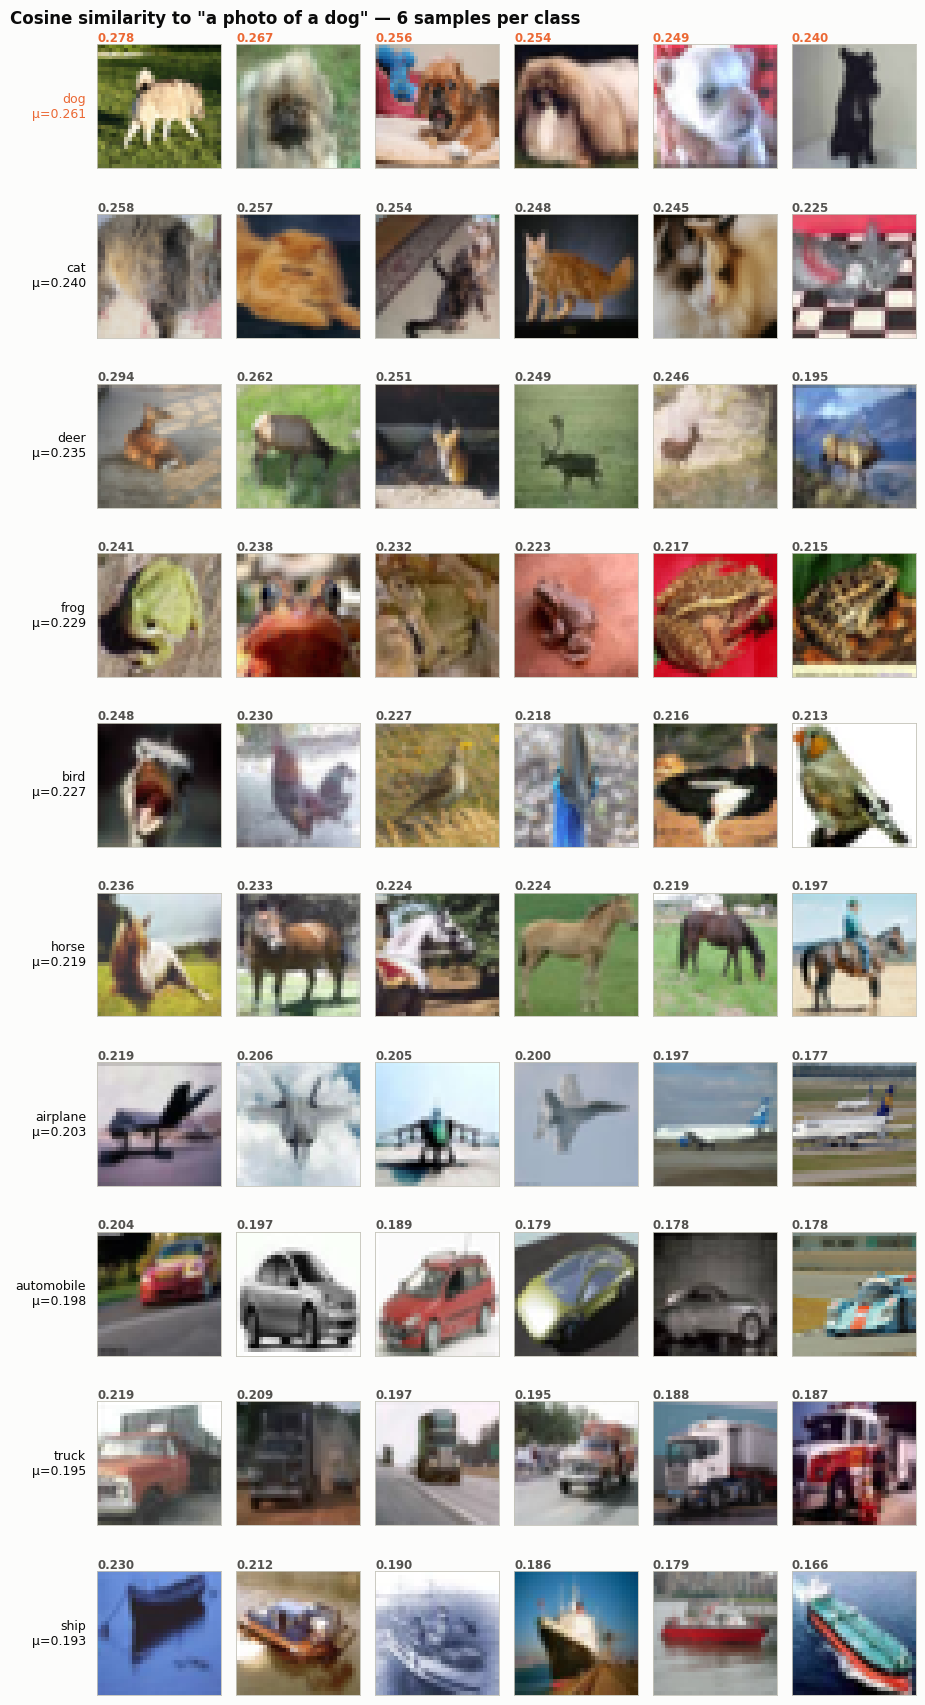

In [10]:
ncols = 6
rng_vis = np.random.default_rng(SEED)
mean_by_class = dict(zip(per_class_stats["class"], per_class_stats["mean_cos"]))
class_order = list(per_class_stats["class"])                 # highest mean first

fig, axes = plt.subplots(len(CLASSES), ncols, figsize=(ncols * 1.55, len(CLASSES) * 1.75))
for r, cname in enumerate(class_order):
    c = CLASSES.index(cname)
    pick = rng_vis.choice(np.where(subset_labels == c)[0], ncols, replace=False)
    pick = pick[np.argsort(-cos_sim[pick])]
    for j, k in enumerate(pick):
        ax = axes[r, j]
        ax.imshow(subset_images[k], interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{cos_sim[k]:.3f}", fontsize=8.5, color=ORANGE if c == target_id else INK2, pad=2)
        for s in ax.spines.values():
            s.set_visible(True); s.set_color(AXIS); s.set_linewidth(0.6)
    axes[r, 0].set_ylabel(f"{cname}\nμ={mean_by_class[cname]:.3f}", rotation=0, ha="right", va="center",
                          fontsize=9, labelpad=8, color=ORANGE if c == target_id else INK)
fig.suptitle(f'Cosine similarity to "{CAPTION}" — 6 samples per class', x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout(); save(fig, "part1_class_gallery.png"); plt.show()

### 6c. Score distribution per class (all 1,000 images)

saved → outputs/part1_similarity_distribution.png


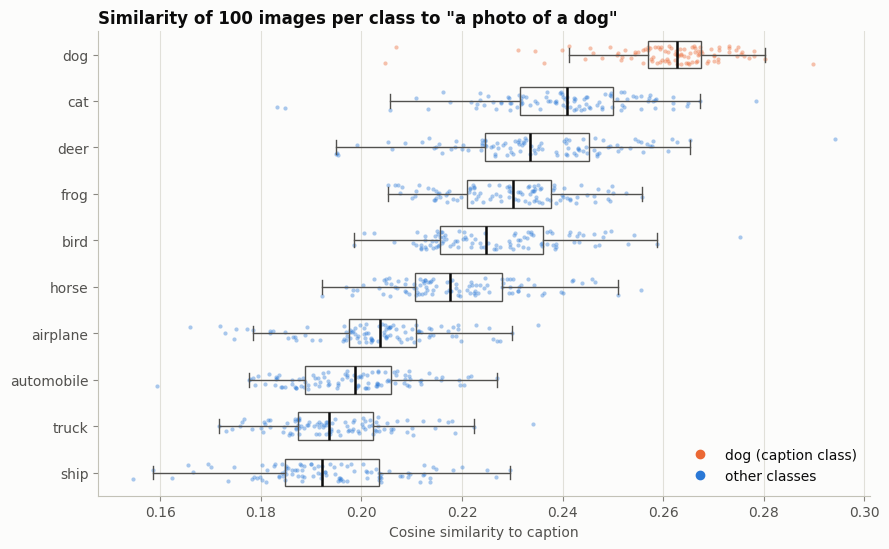

In [11]:
order_cls = [CLASSES.index(c) for c in per_class_stats["class"]][::-1]   # lowest at bottom
rng_jit = np.random.default_rng(SEED)

fig, ax = plt.subplots(figsize=(9, 5.6))
for pos, c in enumerate(order_cls):
    vals = cos_sim[subset_labels == c]
    color = ORANGE if c == target_id else BLUE
    ax.scatter(vals, pos + rng_jit.uniform(-0.2, 0.2, len(vals)), s=9, color=color, alpha=0.4, linewidths=0, zorder=2)
    ax.boxplot(vals, positions=[pos], vert=False, widths=0.6, showfliers=False, patch_artist=True, zorder=3,
               boxprops=dict(facecolor="none", edgecolor=INK2, linewidth=1),
               medianprops=dict(color=INK, linewidth=1.8),
               whiskerprops=dict(color=INK2, linewidth=1), capprops=dict(color=INK2, linewidth=1))
ax.set_yticks(range(len(order_cls))); ax.set_yticklabels([CLASSES[c] for c in order_cls])
ax.set_xlabel("Cosine similarity to caption")
ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.set_title(f'Similarity of 100 images per class to "{CAPTION}"')
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=ORANGE, label=f"{TARGET_CLASS} (caption class)"),
                   Line2D([], [], marker="o", ls="", color=BLUE, label="other classes")],
          loc="lower right", frameon=False)
plt.tight_layout(); save(fig, "part1_similarity_distribution.png"); plt.show()

### 6d. Extension — one caption per class
Repeating the experiment with `"a photo of a {class}"` for every class gives a 10×10 matrix of mean similarities. A strong diagonal means CLIP's text and image spaces are aligned for every CIFAR-10 concept — which is exactly what Part 2 exploits.

saved → outputs/part1_caption_sweep_heatmap.png


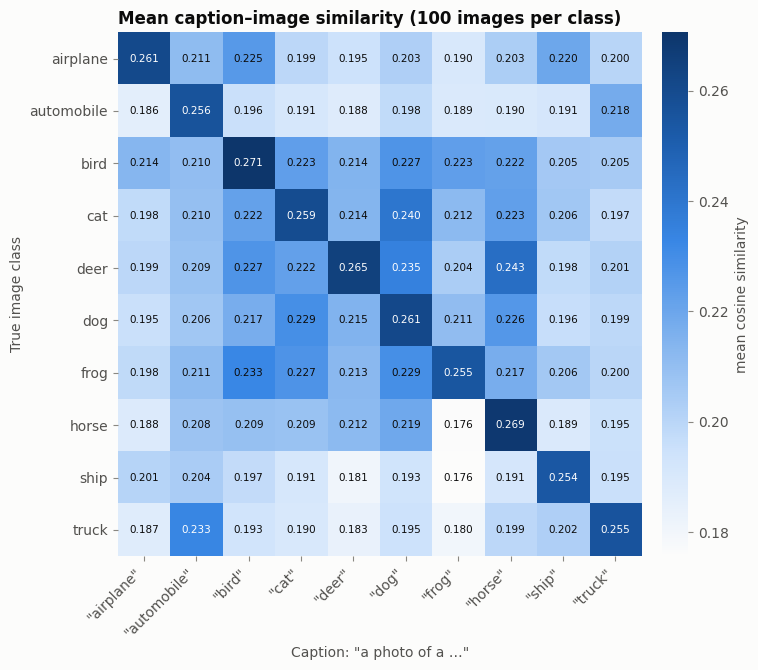

diagonal is row-max for 10/10 classes | argmax accuracy on the 1,000-image subset: 0.879


In [12]:
sweep_captions = [f"a photo of a {c}" for c in CLASSES]
sweep_txt = encode_texts(sweep_captions)                        # (10, D)
sweep_sim = (img_emb_p1 @ sweep_txt.T).numpy()                  # (1000, 10)
mean_mat = np.stack([sweep_sim[subset_labels == c].mean(0) for c in range(len(CLASSES))])   # rows: image class
subset_zs_acc = (sweep_sim.argmax(1) == subset_labels).mean()

fig, ax = plt.subplots(figsize=(8.2, 6.8))
im = ax.imshow(mean_mat, cmap=SEQ_CMAP)
ax.set_xticks(range(10)); ax.set_xticklabels([f'"{c}"' for c in CLASSES], rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
ax.set_xlabel('Caption: "a photo of a …"'); ax.set_ylabel("True image class")
thr = mean_mat.min() + 0.6 * (mean_mat.max() - mean_mat.min())
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{mean_mat[i, j]:.3f}", ha="center", va="center", fontsize=7.5,
                color="#ffffff" if mean_mat[i, j] > thr else INK)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label("mean cosine similarity"); cb.outline.set_visible(False)
ax.set_title("Mean caption–image similarity (100 images per class)")
plt.tight_layout(); save(fig, "part1_caption_sweep_heatmap.png"); plt.show()
print(f"diagonal is row-max for {np.sum(mean_mat.argmax(1) == np.arange(10))}/10 classes | "
      f"argmax accuracy on the 1,000-image subset: {subset_zs_acc:.3f}")

## 7. Findings (Part 1)

In [13]:
pcs = per_class_stats.set_index("class")["mean_cos"]
others = pcs.drop(TARGET_CLASS)
top_rank_of_target = list(pcs.index).index(TARGET_CLASS) + 1
intruders = Counter(CLASSES[subset_labels[k]] for k in rank[:N_PER_CLASS] if subset_labels[k] != target_id)
intruder_txt = ", ".join(f"{c} ({n})" for c, n in intruders.most_common(4)) or "none"

display(Markdown(f'''
**Run results** — caption *"{CAPTION}"* vs. {len(subset_idx):,} CIFAR-10 test images ({N_PER_CLASS}/class), `{MODEL_ID}`

| Metric | Value |
|---|---|
| Cosine range (all images) | {cos_sim.min():.3f} – {cos_sim.max():.3f} |
| Mean cosine, **{TARGET_CLASS}** images | {pcs[TARGET_CLASS]:.4f} (rank {top_rank_of_target} of 10) |
| Closest other class | {others.idxmax()} ({others.max():.4f}) |
| Farthest class | {pcs.idxmin()} ({pcs.min():.4f}) |
| Margin: {TARGET_CLASS} − closest other | {pcs[TARGET_CLASS] - others.max():+.4f} |
| Precision@100 | {prec_at_100:.2f} |
| ROC-AUC ({TARGET_CLASS} vs rest) | {auc:.4f} |
| Non-{TARGET_CLASS} images in top-100 | {intruder_txt} |
| Caption-sweep argmax accuracy (1,000 imgs) | {subset_zs_acc:.3f} |
'''))


**Run results** — caption *"a photo of a dog"* vs. 1,000 CIFAR-10 test images (100/class), `openai/clip-vit-base-patch32`

| Metric | Value |
|---|---|
| Cosine range (all images) | 0.155 – 0.294 |
| Mean cosine, **dog** images | 0.2611 (rank 1 of 10) |
| Closest other class | cat (0.2401) |
| Farthest class | ship (0.1933) |
| Margin: dog − closest other | +0.0210 |
| Precision@100 | 0.76 |
| ROC-AUC (dog vs rest) | 0.9626 |
| Non-dog images in top-100 | cat (14), deer (8), bird (2) |
| Caption-sweep argmax accuracy (1,000 imgs) | 0.879 |


**Interpretation**

1. **Raw cosine scores are compressed; what matters is the ranking.** All 1,000 scores fall between 0.155 and 0.294 (mean 0.220), and the gap between dog (0.261) and the next class, cat (0.240), is only 0.021. CLIP multiplies by its logit scale (100) before the softmax, so that 0.021 becomes a 2.1-logit gap, about 8× in probability. Small cosine differences carry real signal.
2. **The ranking matches real-world similarity.** Dog images score highest, followed by the other animals: cat (0.240), deer (0.235), frog (0.229), bird (0.227), horse (0.219). All four vehicle classes score lowest (0.193–0.203). The embedding space separates animals from vehicles, although CLIP never saw CIFAR-10 labels.
3. **Strong ranking, overlapping distributions.** ROC-AUC is 0.963 and 76 of the top-100 images are dogs. The 24 non-dog images are all animals (cat 14, deer 8, bird 2) and none are vehicles. The single highest-scoring image is a deer (0.294): a small brown four-legged animal on a plain background. The box plot shows dog shifted right but overlapping cat and deer, so a fixed cosine threshold would misclassify many images, while relative ranking works well.
4. **Low resolution limits detail.** CIFAR-10 images are upsampled from 32×32 to 224×224, which removes the fine cues (ears, snout, fur texture) that separate a dog from a cat or deer. This explains why the false positives are look-alike animals.
5. **One caption per class gives a classifier.** With one caption per class, the diagonal is the row maximum for 10/10 classes, and picking the best caption labels the 1,000-image subset with 87.9% accuracy. That is zero-shot classification, evaluated on the full test set in Part 2.

---
# Part 2 — Zero-shot classification on CIFAR-10

**Method:** For each class, build a text "classifier weight" by embedding prompts such as *"a blurry photo of a {class}."*, averaging the normalized embeddings across templates (**prompt ensembling**), and re-normalizing. Each test image is assigned the class whose weight has the highest cosine similarity. No CIFAR-10 training images are used.

We compare a **single template** (`"a photo of a {}."`) against an **8-template ensemble** that includes resolution-aware prompts, which suit CIFAR-10's tiny images.

## 8. Encode all 10,000 test images

In [14]:
cache_path = os.path.join(OUT_DIR, f"cifar10_test_{MODEL_ID.split('/')[-1]}_img_emb.pt")
t0 = time.time()
if os.path.exists(cache_path):
    img_emb_all = torch.load(cache_path)
    print("loaded cached embeddings:", cache_path)
else:
    all_images = [Image.fromarray(x) for x in test_set.data]
    img_emb_all = encode_images(all_images, desc="CIFAR-10 test")
    torch.save(img_emb_all, cache_path)
p2_encode_sec = time.time() - t0
print("image embeddings:", tuple(img_emb_all.shape), f"| {p2_encode_sec:.1f}s")

CIFAR-10 test:   0%|          | 0/40 [00:00<?, ?it/s]

image embeddings: (10000, 512) | 7.7s


## 9. Build zero-shot classifier weights from prompts

In [15]:
SINGLE_TEMPLATE = ["a photo of a {}."]
ENSEMBLE_TEMPLATES = [
    "a photo of a {}.",
    "a blurry photo of a {}.",
    "a low resolution photo of a {}.",
    "a pixelated photo of a {}.",
    "a photo of the small {}.",
    "a photo of the big {}.",
    "a good photo of a {}.",
    "a close-up photo of a {}.",
]

def build_zeroshot_weights(classnames, templates):
    weights = []
    for c in classnames:
        e = encode_texts([t.format(c) for t in templates])      # (T, D), each unit norm
        weights.append(F.normalize(e.mean(0), dim=0))           # average, then re-normalize
    return torch.stack(weights)                                  # (C, D)

W_single   = build_zeroshot_weights(CLASSES, SINGLE_TEMPLATE)
W_ensemble = build_zeroshot_weights(CLASSES, ENSEMBLE_TEMPLATES)
print("classifier weights:", tuple(W_ensemble.shape))

classifier weights: (10, 512)


## 10. Predict & evaluate

In [16]:
def evaluate(W, name):
    logits = LOGIT_SCALE * img_emb_all @ W.T                     # (N, C)
    probs  = logits.softmax(dim=-1).numpy()
    preds  = probs.argmax(1)
    cm     = confusion_matrix(labels_all, preds, labels=range(len(CLASSES)))
    top3   = (np.argsort(-probs, axis=1)[:, :3] == labels_all[:, None]).any(1).mean()
    return {"name": name, "probs": probs, "preds": preds, "cm": cm,
            "top1": (preds == labels_all).mean(), "top3": top3,
            "per_class": cm.diagonal() / cm.sum(1)}

res_single   = evaluate(W_single,   "Single template")
res_ensemble = evaluate(W_ensemble, f"{len(ENSEMBLE_TEMPLATES)}-template ensemble")

summary = pd.DataFrame([{
    "Prompting": r["name"], "Top-1 acc": r["top1"], "Top-3 acc": r["top3"],
    "Mean per-class acc": r["per_class"].mean(),
    "Worst class": f'{CLASSES[r["per_class"].argmin()]} ({r["per_class"].min():.3f})'}
    for r in (res_single, res_ensemble)])
display(summary.style.format({"Top-1 acc": "{:.4f}", "Top-3 acc": "{:.4f}", "Mean per-class acc": "{:.4f}"}).hide(axis="index"))

per_class_df = pd.DataFrame({
    "class": CLASSES,
    "support": res_ensemble["cm"].sum(1),
    "acc_single_template": res_single["per_class"],
    "acc_ensemble": res_ensemble["per_class"],
})
per_class_df["delta"] = per_class_df["acc_ensemble"] - per_class_df["acc_single_template"]
per_class_df = per_class_df.sort_values("acc_ensemble", ascending=False).reset_index(drop=True)
display(per_class_df.style.format({"acc_single_template": "{:.3f}", "acc_ensemble": "{:.3f}", "delta": "{:+.3f}"}).hide(axis="index"))
per_class_df.to_csv(f"{OUT_DIR}/part2_per_class_accuracy.csv", index=False)

print("\nClassification report (ensemble):")
print(classification_report(labels_all, res_ensemble["preds"], target_names=CLASSES, digits=3))

Prompting,Top-1 acc,Top-3 acc,Mean per-class acc,Worst class
Single template,0.8831,0.9746,0.8831,frog (0.715)
8-template ensemble,0.8931,0.9767,0.8931,frog (0.767)


class,support,acc_single_template,acc_ensemble,delta
horse,1000,0.971,0.976,+0.005
ship,1000,0.959,0.964,+0.005
automobile,1000,0.933,0.944,+0.011
truck,1000,0.949,0.941,-0.008
airplane,1000,0.889,0.907,+0.018
dog,1000,0.891,0.884,-0.007
bird,1000,0.897,0.882,-0.015
cat,1000,0.857,0.865,+0.008
deer,1000,0.770,0.801,+0.031
frog,1000,0.715,0.767,+0.052



Classification report (ensemble):
              precision    recall  f1-score   support

    airplane      0.953     0.907     0.929      1000
  automobile      0.925     0.944     0.935      1000
        bird      0.846     0.882     0.863      1000
         cat      0.815     0.865     0.839      1000
        deer      0.910     0.801     0.852      1000
         dog      0.843     0.884     0.863      1000
        frog      0.976     0.767     0.859      1000
       horse      0.834     0.976     0.900      1000
        ship      0.931     0.964     0.947      1000
       truck      0.939     0.941     0.940      1000

    accuracy                          0.893     10000
   macro avg      0.897     0.893     0.893     10000
weighted avg      0.897     0.893     0.893     10000



### 10a. Per-class accuracy

saved → outputs/part2_per_class_accuracy.png


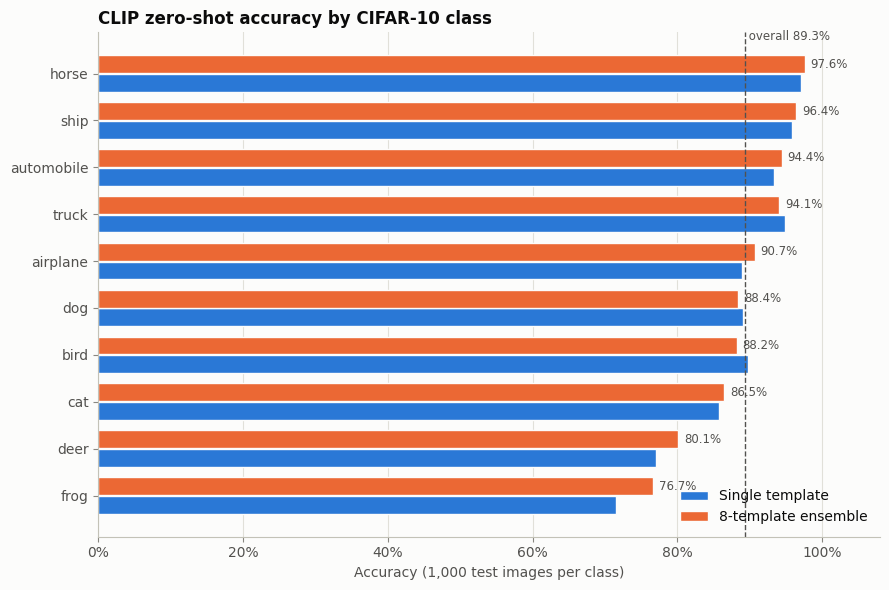

In [17]:
order = list(per_class_df["class"])[::-1]                         # best at top
y = np.arange(len(order)); h = 0.38
acc_s = per_class_df.set_index("class").loc[order, "acc_single_template"].values
acc_e = per_class_df.set_index("class").loc[order, "acc_ensemble"].values

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(y - h / 2 - 0.01, acc_s, height=h, color=BLUE, label=res_single["name"], edgecolor=SURFACE, linewidth=1)
ax.barh(y + h / 2 + 0.01, acc_e, height=h, color=ORANGE, label=res_ensemble["name"], edgecolor=SURFACE, linewidth=1)
for yi, v in zip(y, acc_e):
    ax.text(v + 0.008, yi + h / 2 + 0.01, f"{v:.1%}", va="center", fontsize=8.5, color=INK2)
ax.axvline(res_ensemble["top1"], color=INK2, lw=1, ls="--")
ax.text(res_ensemble["top1"], len(order) - 0.35, f' overall {res_ensemble["top1"]:.1%}', fontsize=8.5, color=INK2, va="bottom")
ax.set_yticks(y); ax.set_yticklabels(order)
ax.set_xlim(0, 1.08); ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.set_xlabel("Accuracy (1,000 test images per class)")
ax.set_title("CLIP zero-shot accuracy by CIFAR-10 class")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); save(fig, "part2_per_class_accuracy.png"); plt.show()

### 10b. Confusion matrix (ensemble)

saved → outputs/part2_confusion_matrix.png


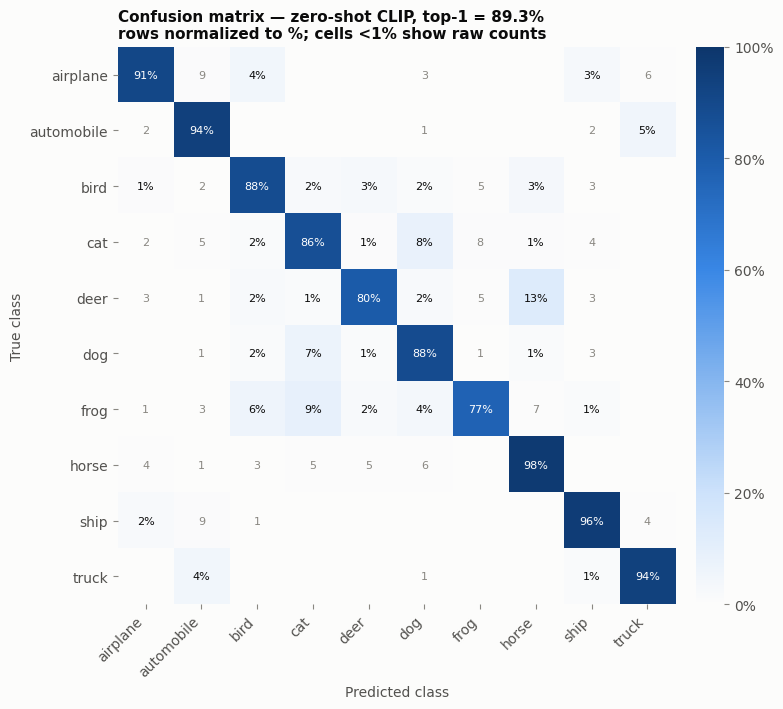

Most frequent confusions (true → predicted):
        deer → horse       131  (13.1% of deer)
        frog → cat          87  (8.7% of frog)
         cat → dog          81  (8.1% of cat)
         dog → cat          70  (7.0% of dog)
        frog → bird         61  (6.1% of frog)
  automobile → truck        51  (5.1% of automobile)


In [18]:
cm = res_ensemble["cm"]
cm_norm = cm / cm.sum(1, keepdims=True)

fig, ax = plt.subplots(figsize=(8.4, 7.2))
im = ax.imshow(cm_norm, cmap=SEQ_CMAP, vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
for i in range(10):
    for j in range(10):
        v = cm_norm[i, j]
        if cm[i, j] == 0: continue
        ax.text(j, i, f"{v:.0%}" if v >= 0.01 else f"{cm[i, j]}", ha="center", va="center", fontsize=8,
                color="#ffffff" if v > 0.5 else (INK if v >= 0.01 else MUTED))
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cb.ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0)); cb.outline.set_visible(False)
ax.set_title(f"Confusion matrix — zero-shot CLIP, top-1 = {res_ensemble['top1']:.1%}\n"
             "rows normalized to %; cells <1% show raw counts", fontsize=11)
plt.tight_layout(); save(fig, "part2_confusion_matrix.png"); plt.show()

pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(f"{OUT_DIR}/part2_confusion_matrix_counts.csv")

off = [(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j]
top_conf = sorted(off, reverse=True)[:6]
print("Most frequent confusions (true → predicted):")
for n, t, p in top_conf:
    print(f"  {t:>10} → {p:<10} {n:4d}  ({n / cm[CLASSES.index(t)].sum():.1%} of {t})")

### 10c. Most confident mistakes

saved → outputs/part2_confident_mistakes.png


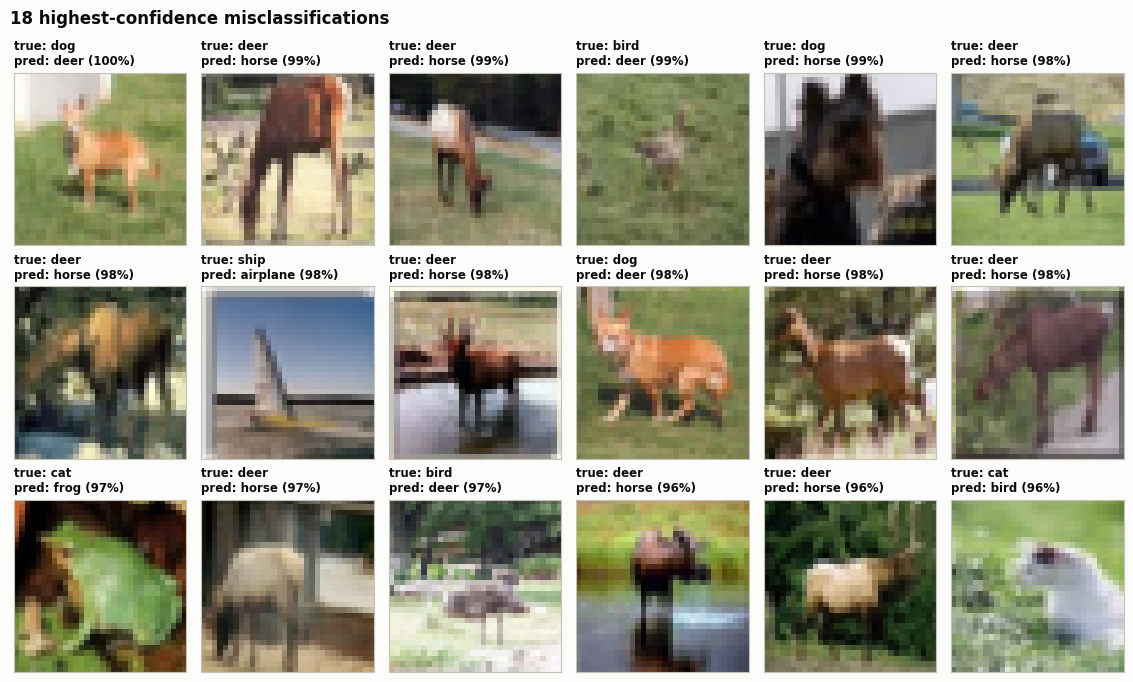

In [19]:
probs, preds = res_ensemble["probs"], res_ensemble["preds"]
wrong = np.where(preds != labels_all)[0]
worst = wrong[np.argsort(-probs[wrong, preds[wrong]])][:18]

fig, axes = plt.subplots(3, 6, figsize=(6 * 1.9, 3 * 2.35))
for ax, k in zip(axes.ravel(), worst):
    ax.imshow(test_set.data[k], interpolation="nearest")
    ax.set_title(f"true: {CLASSES[labels_all[k]]}\npred: {CLASSES[preds[k]]} ({probs[k, preds[k]]:.0%})", fontsize=8.5)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(True); s.set_color(AXIS); s.set_linewidth(0.8)
fig.suptitle("18 highest-confidence misclassifications", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout(); save(fig, "part2_confident_mistakes.png"); plt.show()

## 11. Findings (Part 2)

In [20]:
pc = per_class_df.set_index("class")
best3  = ", ".join(f"{c} ({v:.1%})" for c, v in pc["acc_ensemble"].nlargest(3).items())
worst3 = ", ".join(f"{c} ({v:.1%})" for c, v in pc["acc_ensemble"].nsmallest(3).items())
conf_txt = "; ".join(f"{t}→{p} ({n})" for n, t, p in top_conf[:4])
gain = res_ensemble["top1"] - res_single["top1"]
improved = int((pc["delta"] > 0).sum())

display(Markdown(f'''
**Run results** — `{MODEL_ID}`, CIFAR-10 test set (10,000 images), no training

| Metric | Single template | {len(ENSEMBLE_TEMPLATES)}-template ensemble |
|---|---|---|
| Top-1 accuracy | {res_single["top1"]:.2%} | **{res_ensemble["top1"]:.2%}** |
| Top-3 accuracy | {res_single["top3"]:.2%} | {res_ensemble["top3"]:.2%} |
| Mean per-class accuracy | {res_single["per_class"].mean():.2%} | {res_ensemble["per_class"].mean():.2%} |

- Prompt ensembling changed top-1 accuracy by **{gain:+.2%}** and improved {improved}/10 classes.
- Best classes: {best3}.
- Weakest classes: {worst3}.
- Most frequent confusions (true→pred, count): {conf_txt}.
'''))


**Run results** — `openai/clip-vit-base-patch32`, CIFAR-10 test set (10,000 images), no training

| Metric | Single template | 8-template ensemble |
|---|---|---|
| Top-1 accuracy | 88.31% | **89.31%** |
| Top-3 accuracy | 97.46% | 97.67% |
| Mean per-class accuracy | 88.31% | 89.31% |

- Prompt ensembling changed top-1 accuracy by **+1.00%** and improved 7/10 classes.
- Best classes: horse (97.6%), ship (96.4%), automobile (94.4%).
- Weakest classes: frog (76.7%), deer (80.1%), cat (86.5%).
- Most frequent confusions (true→pred, count): deer→horse (131); frog→cat (87); cat→dog (81); dog→cat (70).


**Interpretation**

1. **89.3% accuracy without any training.** Matching image embeddings to class-name prompts gives 89.31% top-1 and 97.67% top-3 accuracy on the 10,000 test images, without using a single CIFAR-10 training image or label.
2. **Prompt ensembling helps, mostly on the hardest classes.** Averaging 8 templates raised top-1 from 88.31% to 89.31% (+1.0 pt) and improved 7 of 10 classes. The largest gains were on the weakest classes: frog +5.2 pts (71.5→76.7%), deer +3.1, airplane +1.8. Bird (−1.5), truck (−0.8) and dog (−0.7) dipped slightly. The resolution-aware prompts ("blurry", "low resolution") help most where the single prompt was least reliable.
3. **Errors concentrate in look-alike animals.** The largest single confusion is deer→horse (131 images, 13.1% of deer), followed by frog→cat (87), cat↔dog (81 / 70, nearly symmetric) and frog→bird (61). Among vehicles, the only notable confusion is automobile→truck (51). Vehicles, ships and airplanes all reach 91–96%.
4. **Precision and recall are lopsided for some classes.** Horse has the highest recall (97.6%) but only 83.4% precision: it absorbs other four-legged animals, especially deer. Frog is the reverse, with 97.6% precision but 76.7% recall. CLIP rarely predicts "frog" wrongly but misses many frogs, which at 32×32 are small green or brown blobs that get spread across cat, bird and dog.
5. **Some "errors" are label noise or genuine ambiguity.** The highest-confidence mistakes are mostly deer→horse at 96–99% confidence. A few appear mislabeled: one image labeled cat clearly shows a frog. Part of the measured error therefore reflects the dataset rather than the model.
6. **Ways to improve:** a larger backbone (`openai/clip-vit-large-patch14` via `MODEL_ID`), class-specific prompts for the confused pairs (e.g. "a photo of a deer with antlers"), or a linear probe on CLIP features if a small labeled set is allowed.

## 12. Save metrics & run log

In [21]:
metrics = {
    "model": MODEL_ID, "seed": SEED, "device": DEVICE,
    "part1": {
        "caption": CAPTION, "target_class": TARGET_CLASS, "n_images": int(len(subset_idx)),
        "images_per_class": N_PER_CLASS,
        "precision_at_100": float(prec_at_100), "roc_auc": float(auc),
        "mean_cosine_by_class": {c: float(v) for c, v in pcs.items()},
        "caption_sweep_subset_accuracy": float(subset_zs_acc),
    },
    "part2": {
        "n_test_images": int(len(labels_all)),
        "single_template": {"top1": float(res_single["top1"]), "top3": float(res_single["top3"]),
                            "per_class": dict(zip(CLASSES, map(float, res_single["per_class"])))},
        "ensemble": {"templates": ENSEMBLE_TEMPLATES, "top1": float(res_ensemble["top1"]), "top3": float(res_ensemble["top3"]),
                     "per_class": dict(zip(CLASSES, map(float, res_ensemble["per_class"])))},
        "confusion_matrix": res_ensemble["cm"].tolist(), "labels": CLASSES,
    },
}
with open(f"{OUT_DIR}/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

lines = [f"# METRICS — CLIP zero-shot ({MODEL_ID})", "",
         "## Part 1 — caption similarity", f'- Caption: "{CAPTION}" vs {len(subset_idx)} images ({N_PER_CLASS}/class)',
         f"- Precision@100: {prec_at_100:.3f}", f"- ROC-AUC ({TARGET_CLASS} vs rest): {auc:.4f}", "",
         "| Class | Mean cosine |", "|---|---|"] + \
        [f"| {c} | {v:.4f} |" for c, v in pcs.items()] + \
        ["", "## Part 2 — zero-shot CIFAR-10 (10,000 test images)",
         f'- Top-1: single template {res_single["top1"]:.4f} | ensemble {res_ensemble["top1"]:.4f}',
         f'- Top-3: single template {res_single["top3"]:.4f} | ensemble {res_ensemble["top3"]:.4f}', "",
         "| Class | Single template | Ensemble |", "|---|---|---|"] + \
        [f"| {c} | {s:.3f} | {e:.3f} |" for c, s, e in zip(CLASSES, res_single["per_class"], res_ensemble["per_class"])]
with open(f"{OUT_DIR}/METRICS.md", "w") as f:
    f.write("\n".join(lines) + "\n")

total_sec = time.time() - RUN_START
gpu = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "none"
with open(f"{OUT_DIR}/RUN_LOG.txt", "w") as f:
    f.write(f"date: {time.strftime('%Y-%m-%d %H:%M:%S')}\npython: {platform.python_version()}\n"
            f"torch: {torch.__version__}\ntransformers: {transformers.__version__}\ndevice: {DEVICE} ({gpu})\n"
            f"model: {MODEL_ID}\nseed: {SEED}\n"
            f"part1_encode_sec: {p1_encode_sec:.1f}\npart2_encode_sec: {p2_encode_sec:.1f}\ntotal_sec: {total_sec:.1f}\n"
            f"part1_precision_at_100: {prec_at_100:.4f}\npart1_roc_auc: {auc:.4f}\n"
            f"part2_top1_single: {res_single['top1']:.4f}\npart2_top1_ensemble: {res_ensemble['top1']:.4f}\n")

print(open(f"{OUT_DIR}/METRICS.md").read())
print("files:", sorted(os.listdir(OUT_DIR)))

# METRICS — CLIP zero-shot (openai/clip-vit-base-patch32)

## Part 1 — caption similarity
- Caption: "a photo of a dog" vs 1000 images (100/class)
- Precision@100: 0.760
- ROC-AUC (dog vs rest): 0.9626

| Class | Mean cosine |
|---|---|
| dog | 0.2611 |
| cat | 0.2401 |
| deer | 0.2347 |
| frog | 0.2292 |
| bird | 0.2269 |
| horse | 0.2191 |
| airplane | 0.2027 |
| automobile | 0.1978 |
| truck | 0.1949 |
| ship | 0.1933 |

## Part 2 — zero-shot CIFAR-10 (10,000 test images)
- Top-1: single template 0.8831 | ensemble 0.8931
- Top-3: single template 0.9746 | ensemble 0.9767

| Class | Single template | Ensemble |
|---|---|---|
| airplane | 0.889 | 0.907 |
| automobile | 0.933 | 0.944 |
| bird | 0.897 | 0.882 |
| cat | 0.857 | 0.865 |
| deer | 0.770 | 0.801 |
| dog | 0.891 | 0.884 |
| frog | 0.715 | 0.767 |
| horse | 0.971 | 0.976 |
| ship | 0.959 | 0.964 |
| truck | 0.949 | 0.941 |

files: ['METRICS.md', 'RUN_LOG.txt', 'cifar10_test_clip-vit-base-patch32_img_emb.pt', 'metrics.json', 'pa